# Income model

One XGBoost model estimates monthly income, in GEL, for each person in `nbg_synthetic_data/income_dataset.csv`. Training uses 80% of the people. The other 20% is only for the numbers below.

The model states three numbers. **P50** is the estimate. **P10** and **P90** are the low and high ends it still treats as plausible. The distance from P10 to P90 is how confident that estimate is: a narrow band is a firmer statement than a wide one.

Inputs are who the person is, declared remittances, credit-bureau counts, and the open-banking aggregates. The terms, size, and arrears of the loan in the file are left out, because that loan was sized with income already known.

Salary credits in this generated bank history were drawn from declared income, so the test error is optimistic for real clients whose bank salary and registry income disagree.

## Load

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

REPO = Path.cwd().resolve()
if not (REPO / "nbg_synthetic_data" / "income_dataset.csv").is_file():
    REPO = next(p for p in REPO.parents if (p / "nbg_synthetic_data" / "income_dataset.csv").is_file())

df = pd.read_csv(REPO / "nbg_synthetic_data" / "income_dataset.csv")
print(f"{len(df):,} people, {df.shape[1]} columns")
print(
    f"label INCOME_AMOUNT_TOTAL: {df['INCOME_AMOUNT_TOTAL'].min():.0f} – "
    f"{df['INCOME_AMOUNT_TOTAL'].max():.0f} GEL"
)

100,000 people, 111 columns
label INCOME_AMOUNT_TOTAL: 300 – 10000 GEL

## Nulls

Fourteen open-banking columns are blank. A blank means the API did not report that fact (no salary credit, no loan listed, no running balance), not that the file is broken.

Each of those columns gets a `*_missing` flag, computed before any fill. Two amounts that mean "none of this flow" are then filled with 0: `ob_salary_month` and `ob_card_ticket`. The other blanks stay missing. XGBoost sends a missing value down the branch it learned for missing, which is the right treatment for "the API did not say."

In [2]:
FILL_ZERO = ["ob_salary_month", "ob_card_ticket"]
null_cols = [c for c in df.columns if df[c].isna().any()]
before = df[null_cols].isna().sum().rename("missing_before")

for col in null_cols:
    df[f"{col}_missing"] = df[col].isna().astype(np.uint8)
for col in FILL_ZERO:
    df[col] = df[col].fillna(0.0)

after = df[null_cols].isna().sum().rename("missing_after")
null_report = pd.concat([before, after], axis=1)
null_report["flag"] = [f"{c}_missing" for c in null_report.index]
null_report["filled_with_zero"] = null_report.index.isin(FILL_ZERO)
display(null_report)
print(f"{len(null_cols)} missing flags added. {int((df.isna().sum() > 0).sum())} columns still contain blanks.")

14 missing flags added. 12 columns still contain blanks.

<ipython-input-1-725971bcda09>:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{col}_missing"] = df[col].isna().astype(np.uint8)
<ipython-input-1-725971bcda09>:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{col}_missing"] = df[col].isna().astype(np.uint8)
<ipython-input-1-725971bcda09>:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-f

,missing_before,missing_after,flag,filled_with_zero
ob_salary_month,5922,0,ob_salary_month_missing,True
ob_salary_cv,5922,5922,ob_salary_cv_missing,False
ob_salary_day_std,5922,5922,ob_salary_day_std_missing,False
ob_card_ticket,2,0,ob_card_ticket_missing,True
ob_bal_min_ratio,1579,1579,ob_bal_min_ratio_missing,False
ob_bal_mean_ratio,1579,1579,ob_bal_mean_ratio_missing,False
ob_bal_neg_share,1579,1579,ob_bal_neg_share_missing,False
ob_end_balance_ratio,424,424,ob_end_balance_ratio_missing,False
ob_loan_rate_pct,72342,72342,ob_loan_rate_pct_missing,False
ob_loan_age_months,72342,72342,ob_loan_age_months_missing,False


## Features

Low-cardinality categories are one-hot encoded from the training people only, so a level that appears only in the test set becomes zeros. `banks` is a string of one to three banks; it becomes one flag per bank (`bank_tbc`, `bank_bog`, …) instead of 458 combination dummies. `region_name` is kept and the duplicate region code is dropped.

Left out of the model: the identifier, the label, and every column that describes the loan in this row (amount, rate, instalment, product, arrears, score). Those are consequences of a decision that already used income.

In [3]:
ONE_HOT = ["segment", "region_name", "city", "CLIENT_LEGAL_FORM", "SEX", "GeoCitizen"]
PERSON_NUM = ["Age", "INCOME_AMOUNT_SOI04"]
BUREAU = [
    "last1Month",
    "last3Month",
    "last6Month",
    "last12Month",
    "ExistingOperationsDebtor",
    "TerminatedOperationsDebtor",
]
OB = [c for c in df.columns if c.startswith("ob_") and not c.endswith("_missing")]
FLAGS = [c for c in df.columns if c.endswith("_missing")]

bank = df["banks"].str.get_dummies(sep="|").add_prefix("bank_")
df = pd.concat([df, bank], axis=1)
BANK = list(bank.columns)

y = df["INCOME_AMOUNT_TOTAL"].to_numpy(float)
meta = df[["cid"]].copy()
base_cols = PERSON_NUM + BUREAU + OB + FLAGS + BANK + ONE_HOT
work = df[base_cols].copy()
print(f"model columns before one-hot: {work.shape[1]}  ({len(BANK)} bank flags, {len(FLAGS)} missing flags)")
print("one-hot:", ", ".join(ONE_HOT))
print(f"left out of the model: {df.shape[1] - 2 - work.shape[1]} columns besides the label and cid")

model columns before one-hot: 89  (12 bank flags, 14 missing flags)
one-hot: segment, region_name, city, CLIENT_LEGAL_FORM, SEX, GeoCitizen
left out of the model: 46 columns besides the label and cid

## 80 / 20 split

The split is by person, stratified on income deciles so both sides have the same income mix. Seed `20261020`. Ten percent of the training side is held out only to choose the tree depth and when to stop. The 20% test people are not used for that choice.

In [4]:
SEED = 20261020
decile = pd.qcut(y, 10, labels=False, duplicates="drop")
idx = np.arange(len(work))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=decile)
fit_idx, val_idx = train_test_split(
    train_idx, test_size=0.1, random_state=SEED, stratify=decile[train_idx]
)
print(f"train {len(train_idx):,}   of which fit {len(fit_idx):,} / val {len(val_idx):,}")
print(f"test  {len(test_idx):,}")


def one_hot(train: pd.DataFrame, other: pd.DataFrame, cols: list[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    tr = train.drop(columns=cols)
    ot = other.drop(columns=cols)
    pieces_tr, pieces_ot = [tr], [ot]
    for col in cols:
        levels = sorted(train[col].astype(str).unique())
        names = [f"{col}_{level}" for level in levels]
        tr_d = pd.get_dummies(train[col].astype(str), prefix=col).reindex(columns=names, fill_value=0)
        ot_d = pd.get_dummies(other[col].astype(str), prefix=col).reindex(columns=names, fill_value=0)
        pieces_tr.append(tr_d)
        pieces_ot.append(ot_d)
    left, right = pd.concat(pieces_tr, axis=1), pd.concat(pieces_ot, axis=1)
    left.columns = right.columns = (
        left.columns.str.replace(r"[^0-9A-Za-z_]+", "_", regex=True).str.strip("_")
    )
    return left.astype(np.float32), right.astype(np.float32)


X_fit, X_val = one_hot(work.iloc[fit_idx], work.iloc[val_idx], ONE_HOT)
X_train, X_test = one_hot(work.iloc[train_idx], work.iloc[test_idx], ONE_HOT)
if X_train.columns.duplicated().any() or not X_train.columns.equals(X_test.columns):
    raise RuntimeError("feature columns are duplicated or the train and test matrices differ")
y_fit, y_val = y[fit_idx], y[val_idx]
y_train, y_test = y[train_idx], y[test_idx]
print(f"features after one-hot: {X_train.shape[1]}")

train 80,000   of which fit 72,000 / val 8,000
test  20,000
features after one-hot: 127

## Train

One model, three quantiles (`0.1`, `0.5`, `0.9`). Depth is chosen by validation MAE of P50 among 4, 6, and 8. The winning depth is then refit on the full 80%. Where the three quantiles come out of order, they are sorted so P10 ≤ P50 ≤ P90.

In [5]:
def make_model(depth: int, n_estimators: int, early: int | None) -> xgb.XGBRegressor:
    return xgb.XGBRegressor(
        objective="reg:quantileerror",
        quantile_alpha=[0.1, 0.5, 0.9],
        tree_method="hist",
        max_depth=depth,
        learning_rate=0.08,
        n_estimators=n_estimators,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        early_stopping_rounds=early,
        random_state=SEED,
        n_jobs=4,
        verbosity=0,
    )


search = []
for depth in (4, 6, 8):
    candidate = make_model(depth, 400, 40)
    candidate.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    val_pred = np.sort(candidate.predict(X_val), axis=1)
    mae = float(np.mean(np.abs(y_val - val_pred[:, 1])))
    trees = int(candidate.best_iteration) + 1
    search.append({"depth": depth, "trees": trees, "val_MAE": round(mae, 1)})
    print(f"depth {depth}: {trees} trees, validation MAE {mae:.1f} GEL")

search_df = pd.DataFrame(search).sort_values("val_MAE")
best = search_df.iloc[0]
display(search_df.reset_index(drop=True))

model = make_model(int(best["depth"]), int(best["trees"]), None)
model.fit(X_train, y_train, verbose=False)
print(f"refit on the 80%: depth {int(best['depth'])}, {int(best['trees'])} trees")

depth 4: 400 trees, validation MAE 913.1 GEL
depth 6: 400 trees, validation MAE 856.4 GEL
depth 8: 400 trees, validation MAE 835.0 GEL
refit on the 80%: depth 8, 400 trees

,depth,trees,val_MAE
0,8,400,835.0
1,6,400,856.4
2,4,400,913.1


## Metrics on the 20% test people

P50 is scored as a point estimate (MAE, RMSE, median absolute error, MAPE, R²). P10 and P90 are scored by pinball loss, and by how often the true income lands inside the band. A calibrated P10–P90 band covers about 80% of people.

In [6]:
raw = model.predict(X_test)
crossed = float(((raw[:, 0] > raw[:, 1]) | (raw[:, 1] > raw[:, 2])).mean())
pred = np.sort(raw, axis=1)
p10, p50, p90 = pred[:, 0], pred[:, 1], pred[:, 2]


def pinball(actual: np.ndarray, estimate: np.ndarray, q: float) -> float:
    gap = actual - estimate
    return float(np.mean(np.maximum(q * gap, (q - 1) * gap)))


inside = (y_test >= p10) & (y_test <= p90)
band = p90 - p10
rel = band / np.clip(p50, 1, None)
metrics = pd.DataFrame(
    {
        "metric": [
            "MAE, P50 (GEL)",
            "RMSE, P50 (GEL)",
            "median |error|, P50 (GEL)",
            "MAPE, P50 (%)",
            "R², P50",
            "pinball, P10",
            "pinball, P50",
            "pinball, P90",
            "people inside P10–P90 (%)",
            "mean band width (GEL)",
            "median band / P50",
            "rows with crossed quantiles before sorting (%)",
        ],
        "value": [
            round(mean_absolute_error(y_test, p50), 1),
            round(float(np.sqrt(mean_squared_error(y_test, p50))), 1),
            round(float(median_absolute_error(y_test, p50)), 1),
            round(float(np.mean(np.abs(y_test - p50) / y_test) * 100), 1),
            round(float(r2_score(y_test, p50)), 3),
            round(pinball(y_test, p10, 0.1), 1),
            round(pinball(y_test, p50, 0.5), 1),
            round(pinball(y_test, p90, 0.9), 1),
            round(float(inside.mean() * 100), 1),
            round(float(band.mean()), 1),
            round(float(np.median(rel)), 3),
            round(crossed * 100, 2),
        ],
    }
)
display(metrics)

,metric,value
0,"MAE, P50 (GEL)",849.100
1,"RMSE, P50 (GEL)",1425.100
2,"median |error|, P50 (GEL)",370.900
3,"MAPE, P50 (%)",34.800
4,"R², P50",0.595
5,"pinball, P10",168.900
6,"pinball, P50",424.500
7,"pinball, P90",260.300
8,people inside P10–P90 (%),76.200
9,mean band width (GEL),2526.900


## What the model states

Sixteen test people, four from each quarter of the income range. `band_GEL` is P90 − P10. `band_share` is that width divided by P50: 0.30 means the band is 30% of the estimate. Smaller is more confident. `inside` is whether the true income falls in the band.

,cid,actual,p10,p50,p90,band_GEL,band_share,inside
0,C15140,900.1,1104.400024,1416.000000,3858.500000,2754.100098,1.9,False
1,C81117,1007.3,930.099976,1022.799988,2699.699951,1769.699951,1.7,True
2,C59646,1111.3,1044.900024,1068.199951,2107.500000,1062.500000,1.0,True
3,C15705,1513.0,851.400024,2424.000000,4359.200195,3507.699951,1.4,True
4,C33456,1736.6,1273.500000,1623.400024,3035.500000,1762.000000,1.1,True
5,C94221,1854.3,1991.000000,3730.800049,5659.399902,3668.399902,1.0,False
6,C53116,2015.1,1197.800049,2003.900024,2934.800049,1737.000000,0.9,True
7,C40506,2133.2,1774.500000,2219.899902,3739.500000,1965.000000,0.9,True
8,C58099,2779.1,2420.500000,2750.399902,3755.699951,1335.199951,0.5,True
9,C16178,3868.5,3182.899902,4350.600098,5090.399902,1907.599976,0.4,True


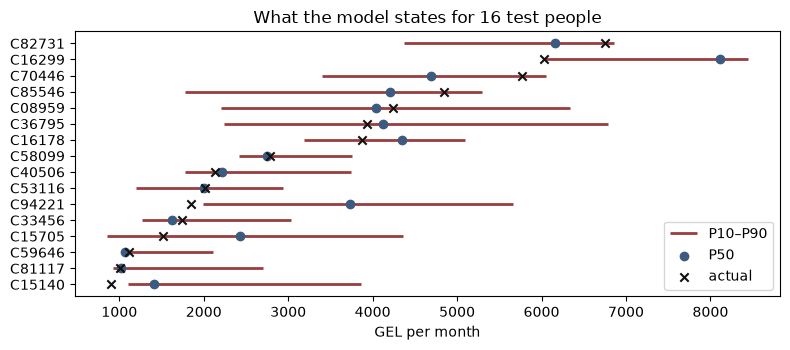

In [7]:
stated = pd.DataFrame(
    {
        "cid": meta.iloc[test_idx]["cid"].to_numpy(),
        "actual": y_test,
        "p10": p10,
        "p50": p50,
        "p90": p90,
        "band_GEL": band,
        "band_share": rel,
        "inside": inside,
    }
)
quarters = pd.qcut(stated["actual"], 4, labels=["low", "mid-low", "mid-high", "high"])
shown = (
    stated.groupby(quarters, observed=True)
    .sample(4, random_state=SEED)
    .sort_values("actual")
    .reset_index(drop=True)
)
display(shown.round(1))

fig, ax = plt.subplots(figsize=(8, 3.6))
order = np.argsort(shown["actual"].to_numpy())
plot = shown.iloc[order].reset_index(drop=True)
ys = np.arange(len(plot))
ax.hlines(ys, plot["p10"], plot["p90"], color="#9b3d3d", linewidth=2, label="P10–P90")
ax.scatter(plot["p50"], ys, color="#3d5a80", zorder=3, label="P50")
ax.scatter(plot["actual"], ys, color="#111111", marker="x", zorder=3, label="actual")
ax.set_yticks(ys, plot["cid"])
ax.set_xlabel("GEL per month")
ax.set_title("What the model states for 16 test people")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Confidence

People are split into five groups by `band_share` on the test set. The narrowest group is where the model is most confident. The table shows whether that confidence is earned: a smaller absolute error, and a band that still covers the true income about 80% of the time.

,people,median_band_share,MAE,inside_pct
confidence_group,,,,
narrowest,4000,0.33,462.27,76.68
narrow,4000,0.63,703.91,77.60
mid,4000,0.86,835.14,77.92
wide,4000,1.14,1151.49,74.40
widest,4000,1.76,1092.65,74.52


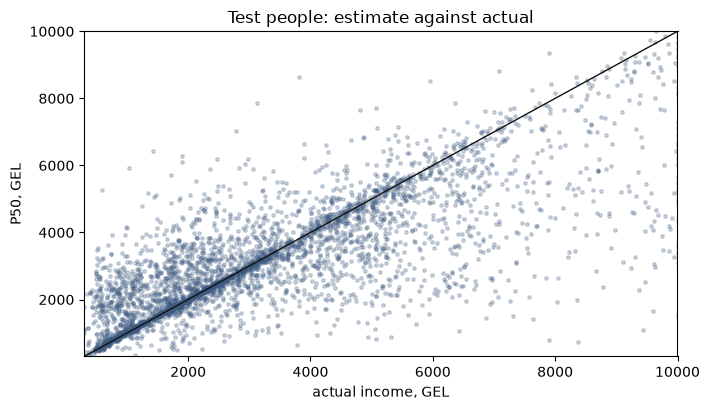

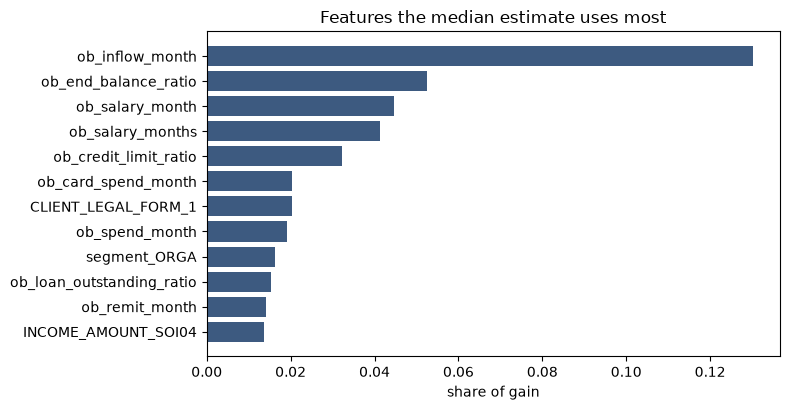

In [8]:
stated["confidence_group"] = pd.qcut(stated["band_share"], 5, labels=["narrowest", "narrow", "mid", "wide", "widest"])
conf = stated.groupby("confidence_group", observed=True).agg(
    people=("actual", "size"),
    median_band_share=("band_share", "median"),
    MAE=("actual", lambda s: np.mean(np.abs(s - stated.loc[s.index, "p50"]))),
    inside_pct=("inside", lambda s: 100 * s.mean()),
)
display(conf.round(2))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
sample = stated.sample(4000, random_state=SEED)
ax.scatter(sample["actual"], sample["p50"], s=6, alpha=0.25, color="#3d5a80")
lim = (300, 10000)
ax.plot(lim, lim, color="#111111", linewidth=1)
ax.set_xlim(*lim)
ax.set_ylim(*lim)
ax.set_xlabel("actual income, GEL")
ax.set_ylabel("P50, GEL")
ax.set_title("Test people: estimate against actual")
fig.tight_layout()
plt.show()

gain = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(gain.index[::-1], gain.to_numpy()[::-1], color="#3d5a80")
ax.set_xlabel("share of gain")
ax.set_title("Features the median estimate uses most")
fig.tight_layout()
plt.show()